In [188]:
from perceval.components.unitary_components import PS, BS
import numpy as np

import perceval as pcvl
from perceval import BasicState

import time
from datetime import datetime
from tqdm import tqdm

import itertools as it
from scipy.optimize import minimize

import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from scipy.optimize import minimize, OptimizeResult

from uncertainties import unumpy

# QLASS VQE 12 modes

## Circuit

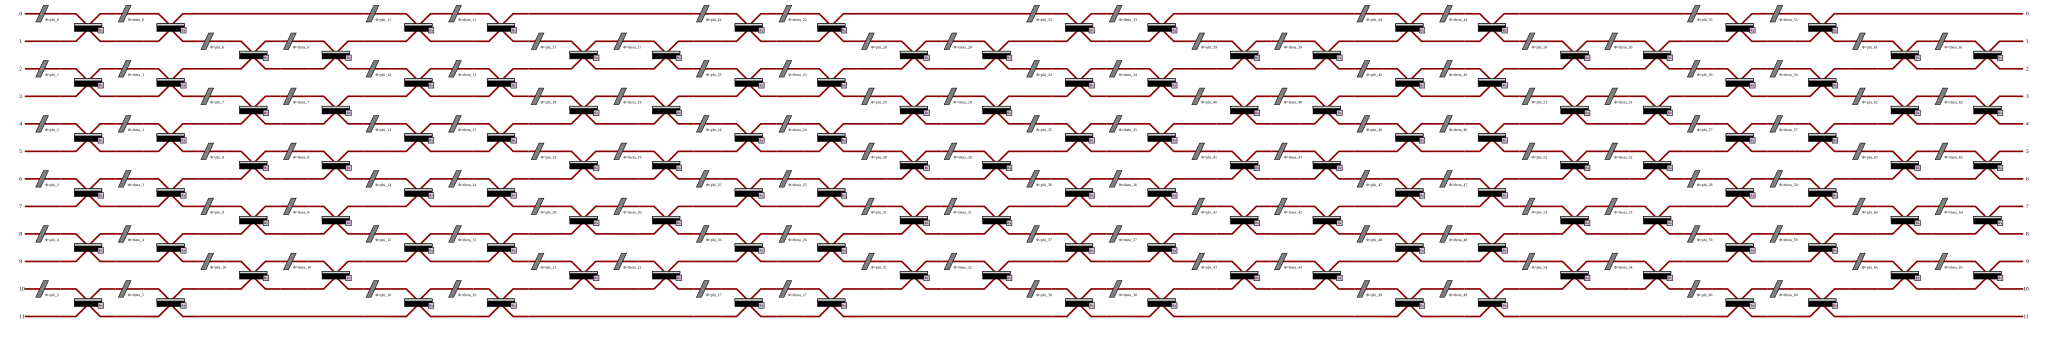

In [44]:
m = 12

circuit = pcvl.components.GenericInterferometer(m,
                                fun_gen = lambda idx: (pcvl.Circuit(2, name='mzi')
                                                       .add(0, PS(pcvl.P(f"phi_{idx}"))))
                                                       .add(0, BS())
                                                       .add(0, PS(pcvl.P(f"theta_{idx}")))
                                                       .add(0, BS()),
                                                shape= pcvl.InterferometerShape.RECTANGLE)
pcvl.pdisplay(circuit)

In [45]:
parameters = circuit.get_parameters()
par_e = parameters[::2]
par_i = parameters[1::2]

In [46]:
out_states = [[1,0,1,0],[0,1,1,0],[1,0,0,1],[0,1,0,1]]
out_states = [[0,0]+j+[0]*6 for j in out_states]
out_states = [pcvl.BasicState(i) for i in out_states]
out_states

[|0,0,1,0,1,0,0,0,0,0,0,0>,
 |0,0,0,1,1,0,0,0,0,0,0,0>,
 |0,0,1,0,0,1,0,0,0,0,0,0>,
 |0,0,0,1,0,1,0,0,0,0,0,0>]

In [85]:
V = 0.85

x = np.arccos(2*V-1)
v1 = BasicState("|{0}>")
v2 = pcvl.StateVector("|{1}>")
phase = complex(np.exp(1j*x))
in_state = BasicState("|0,0>")*(v1+v2)*BasicState("|0>")*(v1+phase*v2)*BasicState("|0,0,0,0,0,0,0>")
in_state
#in_state = pcvl.BasicState("|0,0>")*,0,({0}+np.exp(1j*x)*{1}),0,0,0,0,0,0,0>")

(0.35+0.357I)*|0,0,{1},0,{1},0,0,0,0,0,0,0>+0.5*|0,0,{0},0,{0},0,0,0,0,0,0,0>+0.5*|0,0,{1},0,{0},0,0,0,0,0,0,0>+(0.35+0.357I)*|0,0,{0},0,{1},0,0,0,0,0,0,0>

In [86]:
processor = pcvl.Processor("Naive")

## Circuit simulation

In [87]:
calls = 0

def circ_sim(f_i, f_e):
    N = 100000 # statistics
    
    global calls
    calls +=1

    

    for i,p in enumerate(par_e):
        p.set_value(f_e[i])

    for j,q in enumerate(par_i):
        q.set_value(f_i[j])

    processor.set_circuit(circuit)
    simulator = pcvl.SimulatorFactory().build(processor)

    P_I = []

    for s in out_states:
        p_I = simulator.probability(in_state,s)
        P_I.append(p_I)

    PP = np.array(P_I)

    CC = np.random.poisson(PP*N)
    

    return CC

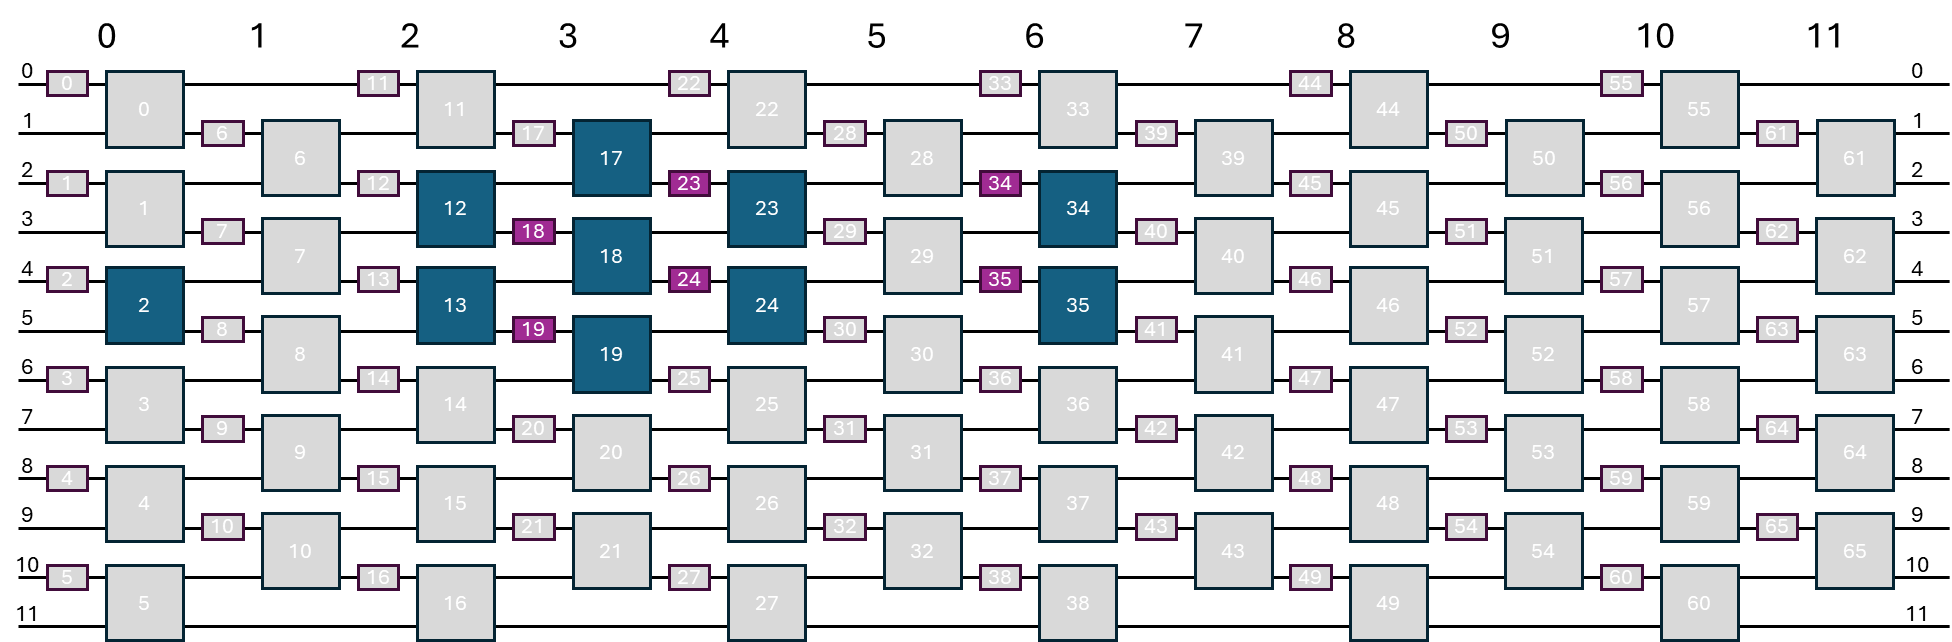

## Cost function evaluation

In [88]:
def P_calc(x, inv = False):
    v_I = [12,13,23,24]
    v_E = [18,19,23,24,34,35]
    v_IR = [17,18,19]
    v_M = [34,35]
    inv_c = 2
    
    # inizializzo il vettore
    f_I = np.full(66,np.pi)
    f_E = np.zeros(66)
    
    # preparo il circuito per generare lo stato
    f_I[v_IR] = [np.arccos(1/3)]*3
    f_I[v_I] = x[:4]
    f_E[v_E] = x[4:]

    if inv:
        f_I[inv_c] = 0

    # misure
    f_I[v_M] = [np.pi, np.pi/2]
    f_E[v_M] = [0]*2
    P_ZX = circ_sim(f_I,f_E)

    f_I[v_M] = [np.pi/2]*2
    f_E[v_M] = [0]*2
    P_XX = circ_sim(f_I,f_E)

    return P_ZX,P_XX

In [89]:
def S1(x, inv = False, Error = False):
    n = len(x)

    P_ZX, P_XX = P_calc(x,inv)

    if Error:
        P_ZX = unumpy.uarray(P_ZX, np.sqrt(P_ZX+1))
        P_XX = unumpy.uarray(P_XX, np.sqrt(P_XX+1))
        
    # calcolo hamiltoniana
    
    V_AI = [1,-1,1,-1]
    V_IA = [1,1,-1,-1]
    V_AB = [1,-1,-1,1]
    
    E_II = 1
    E_ZI = np.dot(V_AI,P_ZX)/np.sum(P_ZX)
    E_ZX = np.dot(V_AB,P_ZX)/np.sum(P_ZX)
    E_XI = np.dot(V_AI,P_XX)/np.sum(P_XX)
    E_IX = np.dot(V_IA,P_XX)/np.sum(P_XX)
    E_XX = np.dot(V_AB,P_XX)/np.sum(P_XX)

    #a,b,c,d,e = -0.340, 0.394, 0.394, 0.011, -0.181
    a,b,c,d,e,f =  0.15619, 0.09699, -0.30923, -0.32671, -0.66681, 0.11017

    H = a*E_II+b*E_ZI+c*E_IX+d*E_ZX+e*E_XI+f*E_XX
    
    #calcolo derivata
    if not Error:
        grad_H = []
        for i in range(n):
            x_s = np.copy(x)
            x_s[i] += np.pi/2
            P_ZX1, P_XX1 = P_calc(x_s,inv)
            
            x_s = np.copy(x)
            x_s[i] -= np.pi/2
            P_ZX2, P_XX2 = P_calc(x_s,inv)
    
            DP_ZX, DP_XX = (P_ZX1-P_ZX2)/2, (P_XX1-P_XX2)/2
    
            D_II = 0
            D_ZI = np.dot(V_AI,DP_ZX)/np.sum(P_ZX)-E_ZI*np.sum(DP_ZX)/np.sum(P_ZX)
            D_ZX = np.dot(V_AB,DP_ZX)/np.sum(P_ZX)-E_ZX*np.sum(DP_ZX)/np.sum(P_ZX)
            D_XI = np.dot(V_AI,DP_XX)/np.sum(P_XX)-E_XI*np.sum(DP_XX)/np.sum(P_XX)
            D_IX = np.dot(V_IA,DP_XX)/np.sum(P_XX)-E_IX*np.sum(DP_XX)/np.sum(P_XX)
            D_XX = np.dot(V_AB,DP_XX)/np.sum(P_XX)-E_XX*np.sum(DP_XX)/np.sum(P_XX)
    
            DH = a*D_II+b*D_ZI+c*D_IX+d*D_ZX+e*D_XI+f*D_XX
    
            grad_H.append(DH)
            
    
        return H, np.array(grad_H)
    else:
        return H.nominal_value, H.std_dev

def S(x):
    H1,Grad1 = S1(x)
    H2,Grad2 = S1(x,True)
    #return H1,Grad1
    return 3/4*H1+1/4*H2, 3/4*Grad1+1/4*Grad2

# Minimizzazione

In [182]:
EE = []
EE1 = []
EE2 = []

EE_e = []
EE1_e = []
EE2_e = []

def callback(x):
    global EE
    v1,e1 = S1(x, Error = True)
    v2,e2 = S1(x,True, Error = True)
    
    EE.append(3/4*v1+1/4*v2)
    EE1.append(v1)
    EE2.append(v2)

    EE_e.append(3/4*e1+1/4*e2)
    EE1_e.append(e1)
    EE2_e.append(e2)
    
    plt.figure(1)
    plt.clf()
    plt.subplot(121)
    plt.errorbar(range(len(EE)),EE,EE_e,fmt = 'g.')
    plt.plot([-0.1,len(EE)-0.9],[-0.671,-0.671],'g')

    plt.subplot(122)
    plt.errorbar(range(len(EE1)),EE1,EE1_e,fmt = 'b.')
    plt.errorbar(range(len(EE2)),EE2,EE2_e, fmt = 'r.')
    plt.plot([-0.1,len(EE1)-0.9],[-0.755,-0.755],'b')
    plt.plot([-0.1,len(EE1)-0.9],[-0.419,-0.419],'r')
    plt.pause(0.1)
    

In [183]:
r0 = np.random.uniform(0,2*np.pi,10)

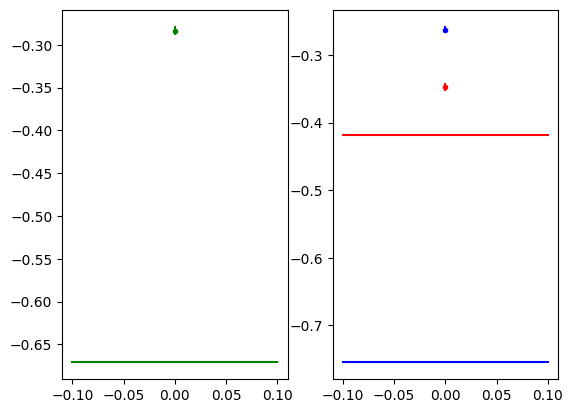

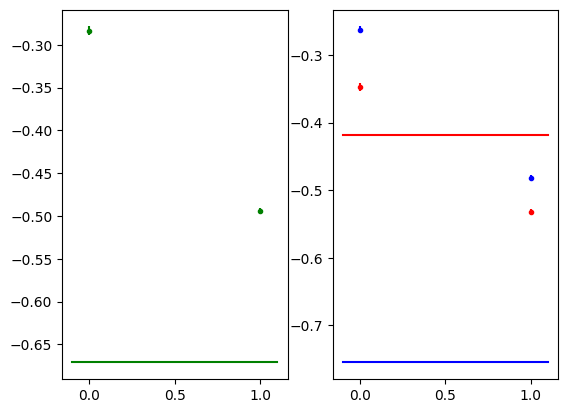

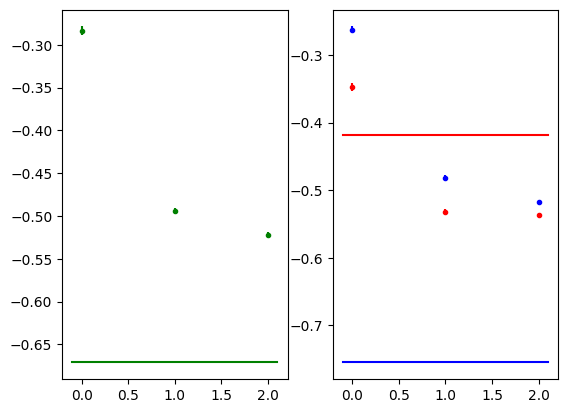

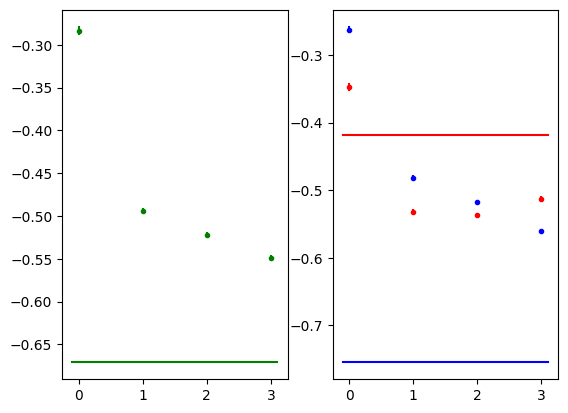

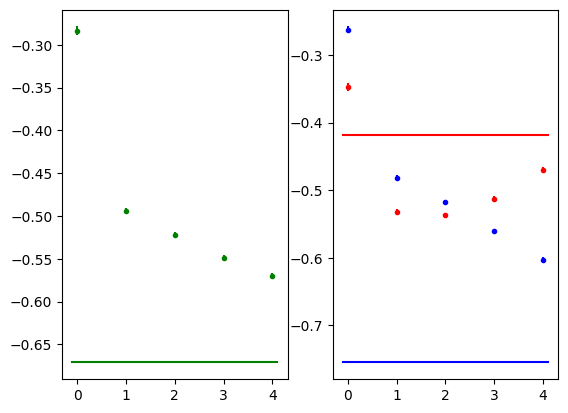

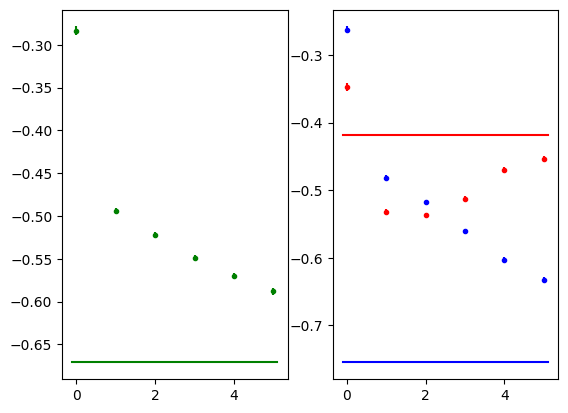

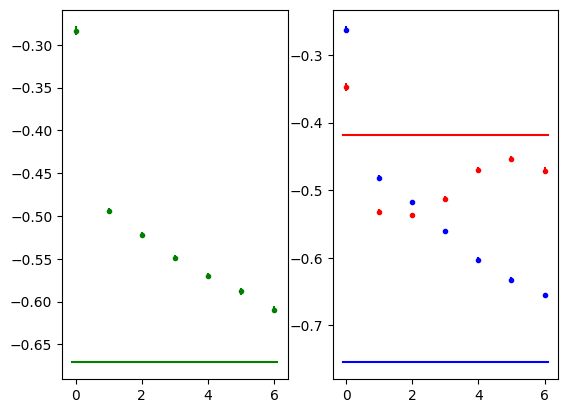

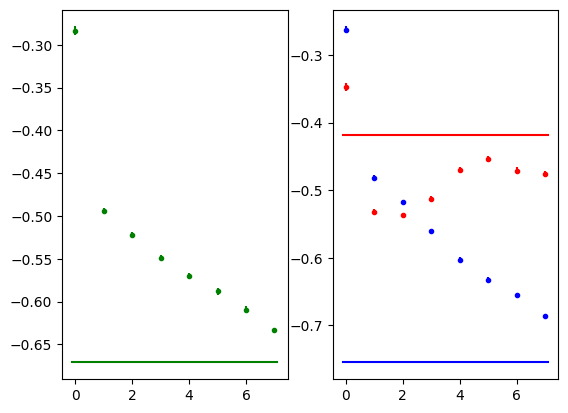

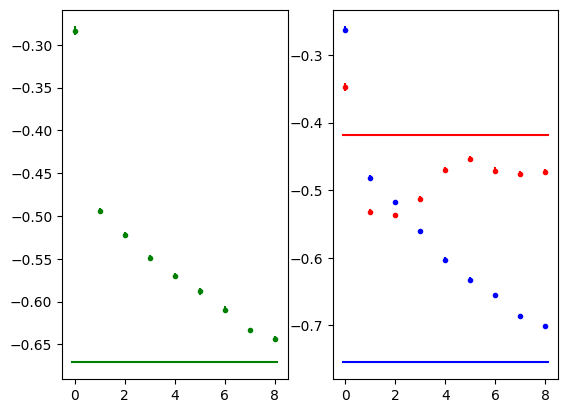

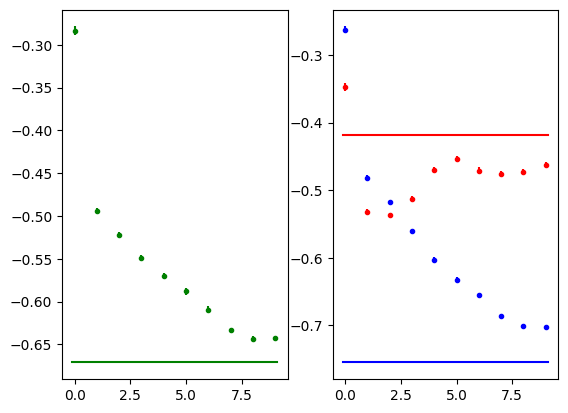

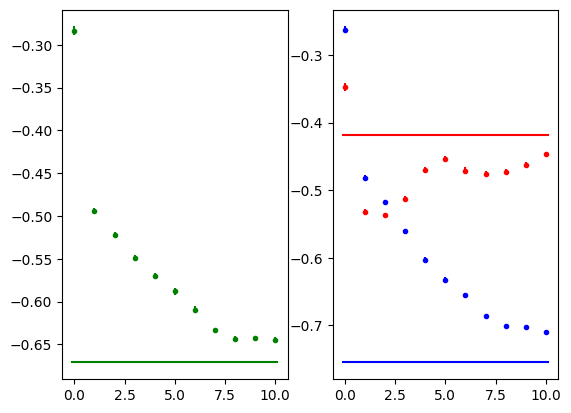

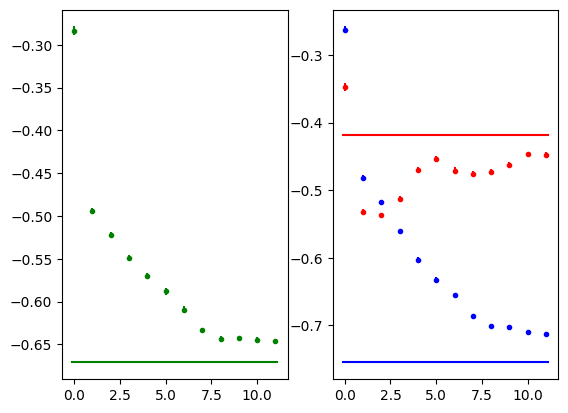

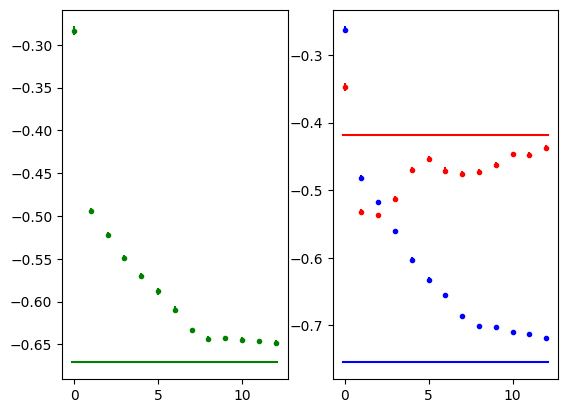

restart


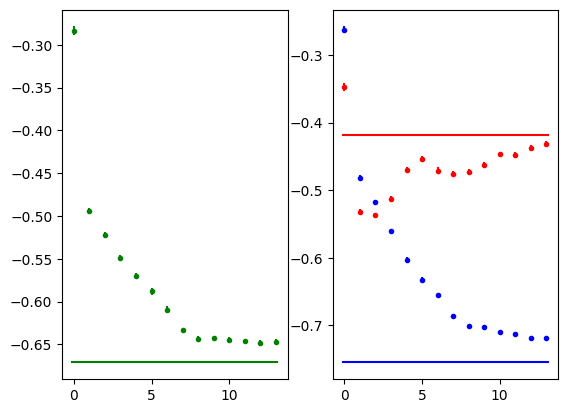

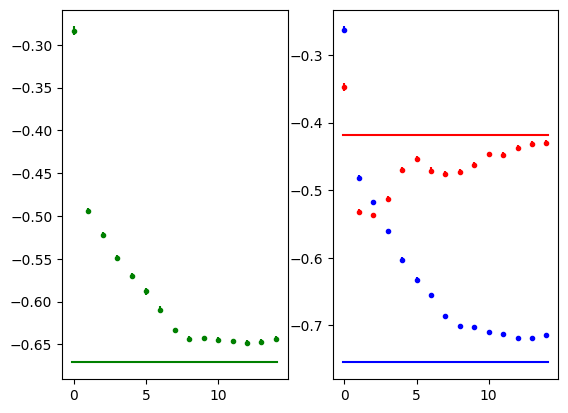

restart


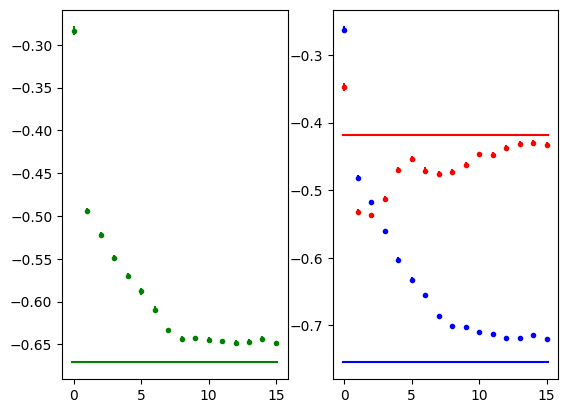

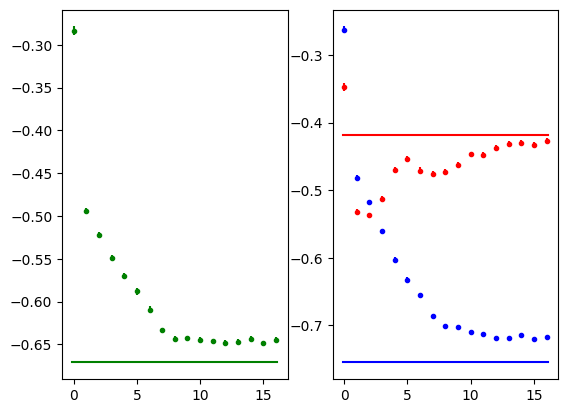

restart


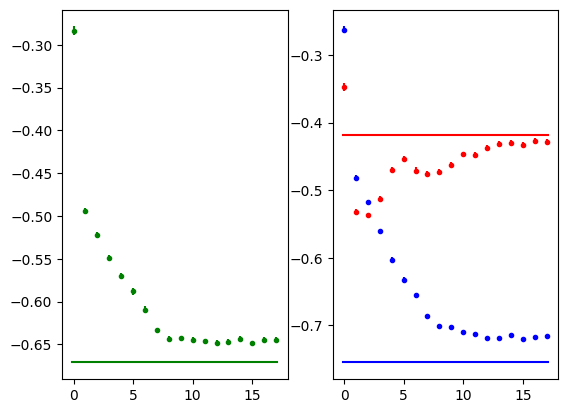

In [184]:
N_s = []

res = minimize(S, r0, method = 'BFGS', jac = True, callback = callback)
N_s.append(len(EE)-1)
print('restart')
res = minimize(S, res.x, method = 'BFGS', jac = True, callback = callback)
N_s.append(len(EE)-1)
print('restart')
res = minimize(S, res.x, method = 'BFGS', jac = True, callback = callback)
N_s.append(len(EE)-1)
print('restart')
res = minimize(S, res.x, method = 'BFGS', jac = True, callback = callback)
N_s.append(len(EE)-1)


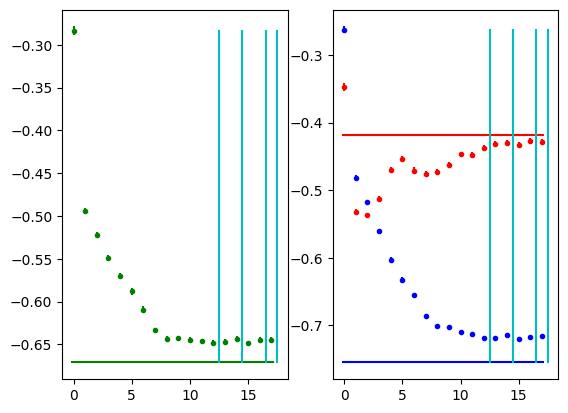

In [185]:
plt.figure(1)
plt.title("Minimization")

plt.clf()
plt.subplot(121)
plt.errorbar(range(len(EE)),EE,EE_e,fmt = 'g.')
plt.plot([-0.1,len(EE)-0.9],[-0.671,-0.671],'g')
for n in N_s:
    plt.plot([n+0.5,n+0.5],[-0.671,max(EE)],'c')

plt.subplot(122)
plt.errorbar(range(len(EE1)),EE1,EE1_e,fmt = 'b.')
plt.errorbar(range(len(EE2)),EE2,EE2_e, fmt = 'r.')
plt.plot([-0.1,len(EE1)-0.9],[-0.755,-0.755],'b')
plt.plot([-0.1,len(EE1)-0.9],[-0.419,-0.419],'r')
for n in N_s:
    plt.plot([n+0.5,n+0.5],[-0.755,max(EE1+EE2)],'c')



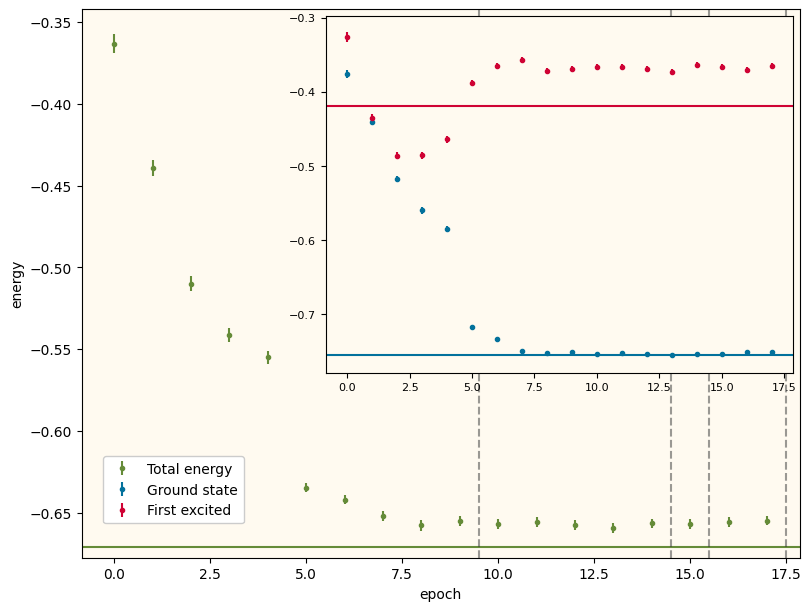

In [206]:
plt.style.use('default')

# from mpl_toolkits.axes_grid1.inset_locator import inset_axes

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)

# --- Main plot (EE only) ---
ax.errorbar(range(len(EE)), EE, EE_e, fmt='.', color='XKCD:moss green', label="Total energy")

ax.axhline(-0.671, color='XKCD:moss green', linestyle='-')

for n in N_s:
    ax.axvline(n + 0.5, color='XKCD:dark grey', linestyle='--', alpha=0.5)

ax.set_ylabel("energy")
ax.set_xlabel("epoch")
ax.set_facecolor('#FFFAF0')

# --- Inset (EE1 and EE2) ---
axins = inset_axes(ax, width="65%", height="65%", loc='upper right')

axins.errorbar(range(len(EE1)), EE1, EE1_e, fmt='.', color='XKCD:ocean blue', label="Ground state")
axins.errorbar(range(len(EE2)), EE2, EE2_e, fmt='.', color='XKCD:cherry', label="First excited")

axins.axhline(-0.755, color='XKCD:ocean blue', linestyle='-')
axins.axhline(-0.419, color='XKCD:cherry', linestyle='-')

# for n in N_s:
    # axins.axvline(n + 0.5, color='XKCD:dark grey', linestyle='--', alpha=0.5)

axins.set_facecolor('#FFFAF0')
axins.tick_params(labelsize=8)

handles_main, labels_main = ax.get_legend_handles_labels()
handles_inset, labels_inset = axins.get_legend_handles_labels()

ax.legend(handles_main + handles_inset,
          labels_main + labels_inset,
          loc='lower left',
          bbox_to_anchor=(0.02, 0.05),
          bbox_transform=ax.transAxes,
          framealpha=1)


time = datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
# plt.savefig(f'Figures/minimization_inset_{time}.pdf')